# Predictive Maintenance with a Full MLOps Loop
**validate → train → track → tune → monitor → explain → decide**

Unplanned downtime on a production line costs far more than a planned tool change. This notebook walks through the full system behind this repo: it classifies each machine reading as healthy or one of four failure modes, and then checks whether the deployed model can still be trusted when operating conditions change.

All logic lives in `src/predmaint/`. This notebook calls it step by step and shows the evidence.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, display
from predmaint import config as C
from predmaint.data import load_batches, validate
from predmaint.features import add_features, strain_index
from predmaint.train import split_and_resample, compare_models, tune_and_register, evaluate
from predmaint.monitor import drift_report
from predmaint.explain import shap_by_class, plot_shap_by_class
from predmaint.plots import plot_eda
pd.set_option("display.precision", 4)

## 1. Data contract
Every batch must pass a Pandera schema with physical ranges before it reaches the model. Passing the contract means a batch is *valid*. It does not mean the batch is *in-distribution*, which section 5 checks separately.

In [2]:
batches = load_batches()
pd.DataFrame([validate(df, name) for name, df in batches.items()])

,batch,rows,valid,violations
0,baseline,6993,True,0
1,stable,1499,True,0
2,heavy_load,1499,True,0


## 2. What the data looks like
96.7% of readings are healthy, and the rarest failure (tool wear) has only 30 examples. That makes accuracy a misleading metric here.

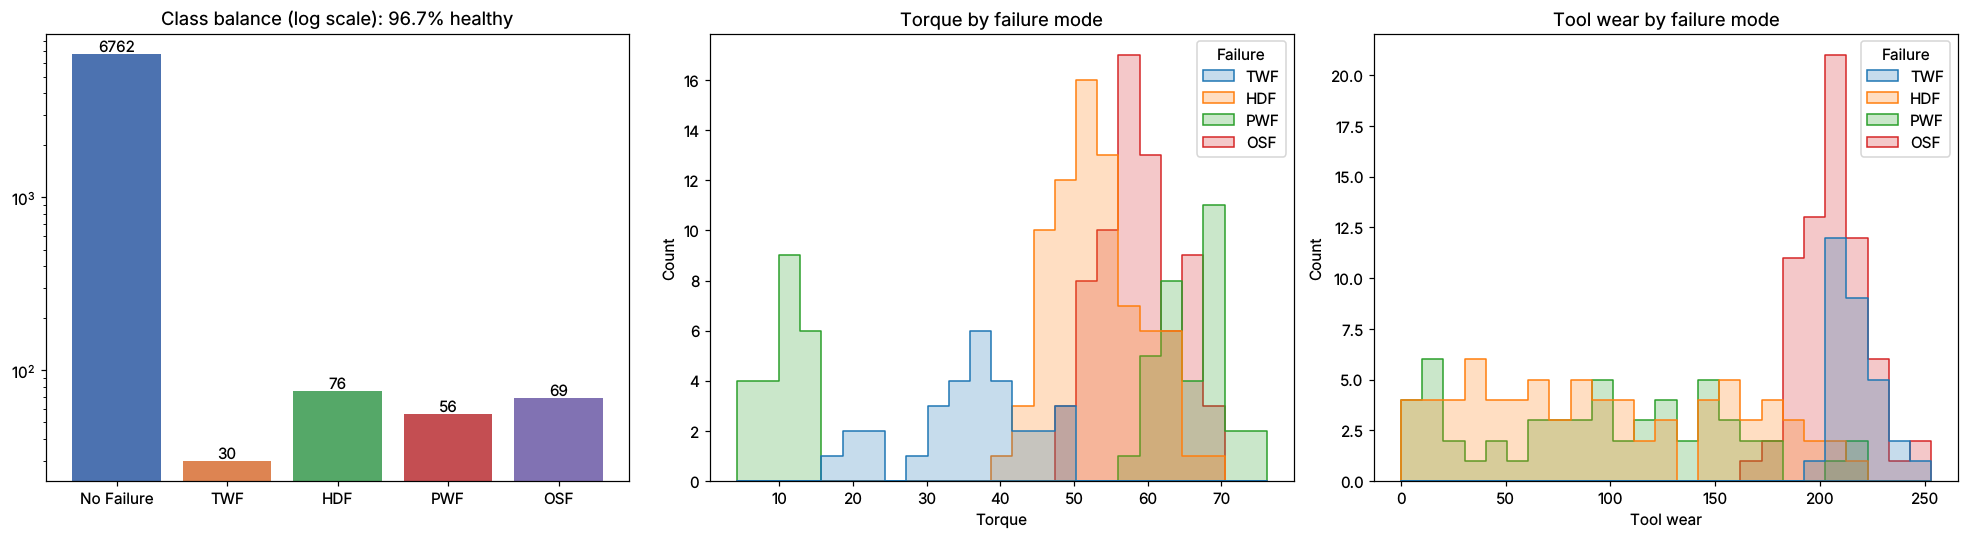

,Power_W,Temp_diff,Torque,Tool wear
Failure_Type,,,,
HDF,7403.55,8.23,53.00,97.68
No Failure,6248.24,10.01,39.65,106.40
OSF,8216.07,10.07,58.54,206.23
PWF,6664.38,9.82,43.42,95.54
TWF,5763.09,9.97,35.66,216.20


In [3]:
batches = {k: add_features(v) for k, v in batches.items()}
base = batches["baseline"]
plot_eda(base, C.FIGURES_DIR / "eda_overview.png")
display(Image(C.FIGURES_DIR / "eda_overview.png"))
base.groupby(base[C.TARGET].map(C.CLASS_NAMES))[["Power_W", "Temp_diff", "Torque", "Tool wear"]].mean().round(2)

Two physics-based features are added: **Power_W = Torque × ω** (mechanical power) and **Temp_diff = process − air temperature** (heat-dissipation headroom). HDF machines show a clearly lower Temp_diff, and OSF machines run at the highest power.

## 3. Model comparison (tracked in MLflow)
The data is split first (stratified 80/20) and then SMOTE (k=3) is applied **to the training part only**, so no synthetic points leak into validation. Models are ranked by macro-F1.

In [4]:
X_res, y_res, X_val, y_val, y_tr = split_and_resample(base)
print("train class counts before SMOTE:", y_tr.value_counts().sort_index().to_dict())
print("after SMOTE:", pd.Series(y_res).value_counts().sort_index().to_dict())
board = compare_models(X_res, y_res, X_val, y_val)
board

train class counts before SMOTE: {0: 5409, 1: 24, 2: 61, 3: 45, 4: 55}
after SMOTE: {0: 5409, 1: 5409, 2: 5409, 3: 5409, 4: 5409}


,macro_f1,weighted_f1,accuracy,f1_NoFailure,f1_TWF,f1_HDF,f1_PWF,f1_OSF
XGBoost,0.7481,0.9851,0.9843,0.9922,0.1333,0.9655,0.8800,0.7692
RandomForest,0.7355,0.9855,0.9850,0.9926,0.0000,0.9286,0.9565,0.8000
LightGBM,0.7296,0.9851,0.9843,0.9922,0.0000,0.9655,0.8333,0.8571
LogisticRegression,0.5312,0.9328,0.9042,0.9483,0.1449,0.4545,0.4583,0.6500


## 4. Tuning + registry
Optuna's TPE sampler runs 30 trials on macro-F1. The winner is logged and registered as `PredMaint_XGBoost` with the `production` alias.

In [5]:
model, study, tuned, version = tune_and_register(X_res, y_res, X_val, y_val)
print(f"baseline XGBoost {board.loc['XGBoost','macro_f1']:.4f} -> tuned {tuned['macro_f1']:.4f}  (registry v{version})")
pd.Series(tuned).round(4)

baseline XGBoost 0.7481 -> tuned 0.7672  (registry v1)


macro_f1        0.7672
weighted_f1     0.9828
accuracy        0.9771
f1_NoFailure    0.9885
f1_TWF          0.0690
f1_HDF          0.9655
f1_PWF          0.9167
f1_OSF          0.8966
dtype: float64

## 5. Monitoring two production batches

In [6]:
rows = {}
for name in ("stable", "heavy_load"):
    summary, table = drift_report(base, batches[name], C.DRIFT_DIR / f"drift_{name}.html")
    perf = evaluate(batches[name][C.TARGET], model.predict(batches[name][C.FEATURES]))
    rows[name] = {**summary, "macro_f1": perf["macro_f1"], "f1_OSF": perf["f1_OSF"],
                  "OSF_share_%": (batches[name][C.TARGET] == 4).mean() * 100,
                  "strain>11k_%": (strain_index(batches[name]) > 11_000).mean() * 100}
    print(f"--- {name}"); display(table)
pd.DataFrame(rows).T

--- stable


,feature,drift,wasserstein,ref_mean,batch_mean,delta_pct
0,Air temperature,False,0.0548,300.01,299.92,-0.03
1,Rotational speed,False,0.0526,1539.02,1530.17,-0.58
2,Torque,False,0.0400,40.00,40.22,0.56
3,Process temperature,False,0.0244,310.00,310.00,-0.00
4,Tool wear,False,0.0181,107.68,108.20,0.48


--- heavy_load


,feature,drift,wasserstein,ref_mean,batch_mean,delta_pct
0,Tool wear,True,0.6455,107.68,148.87,38.25
1,Torque,True,0.4739,40.00,44.72,11.82
2,Rotational speed,True,0.2354,1539.02,1497.07,-2.73
3,Process temperature,False,0.0377,310.00,310.01,0.00
4,Air temperature,False,0.0344,300.01,300.05,0.01


,dataset_drift,drifted_features,n_features,macro_f1,f1_OSF,OSF_share_%,strain>11k_%
stable,False,0,5,0.7423,0.8125,1.0007,1.4009
heavy_load,True,3,5,0.5317,0.6257,3.8692,11.4076


The stable batch shows no drift. The heavy-load batch drifts on **tool wear (+38%)**, **torque (+12%)** and **rotational speed (−3%)**. Overstrain cases become 4× more common, and the model's OSF F1 drops from 0.90 to 0.63.

## 6. Explaining each failure mode (SHAP, per class)

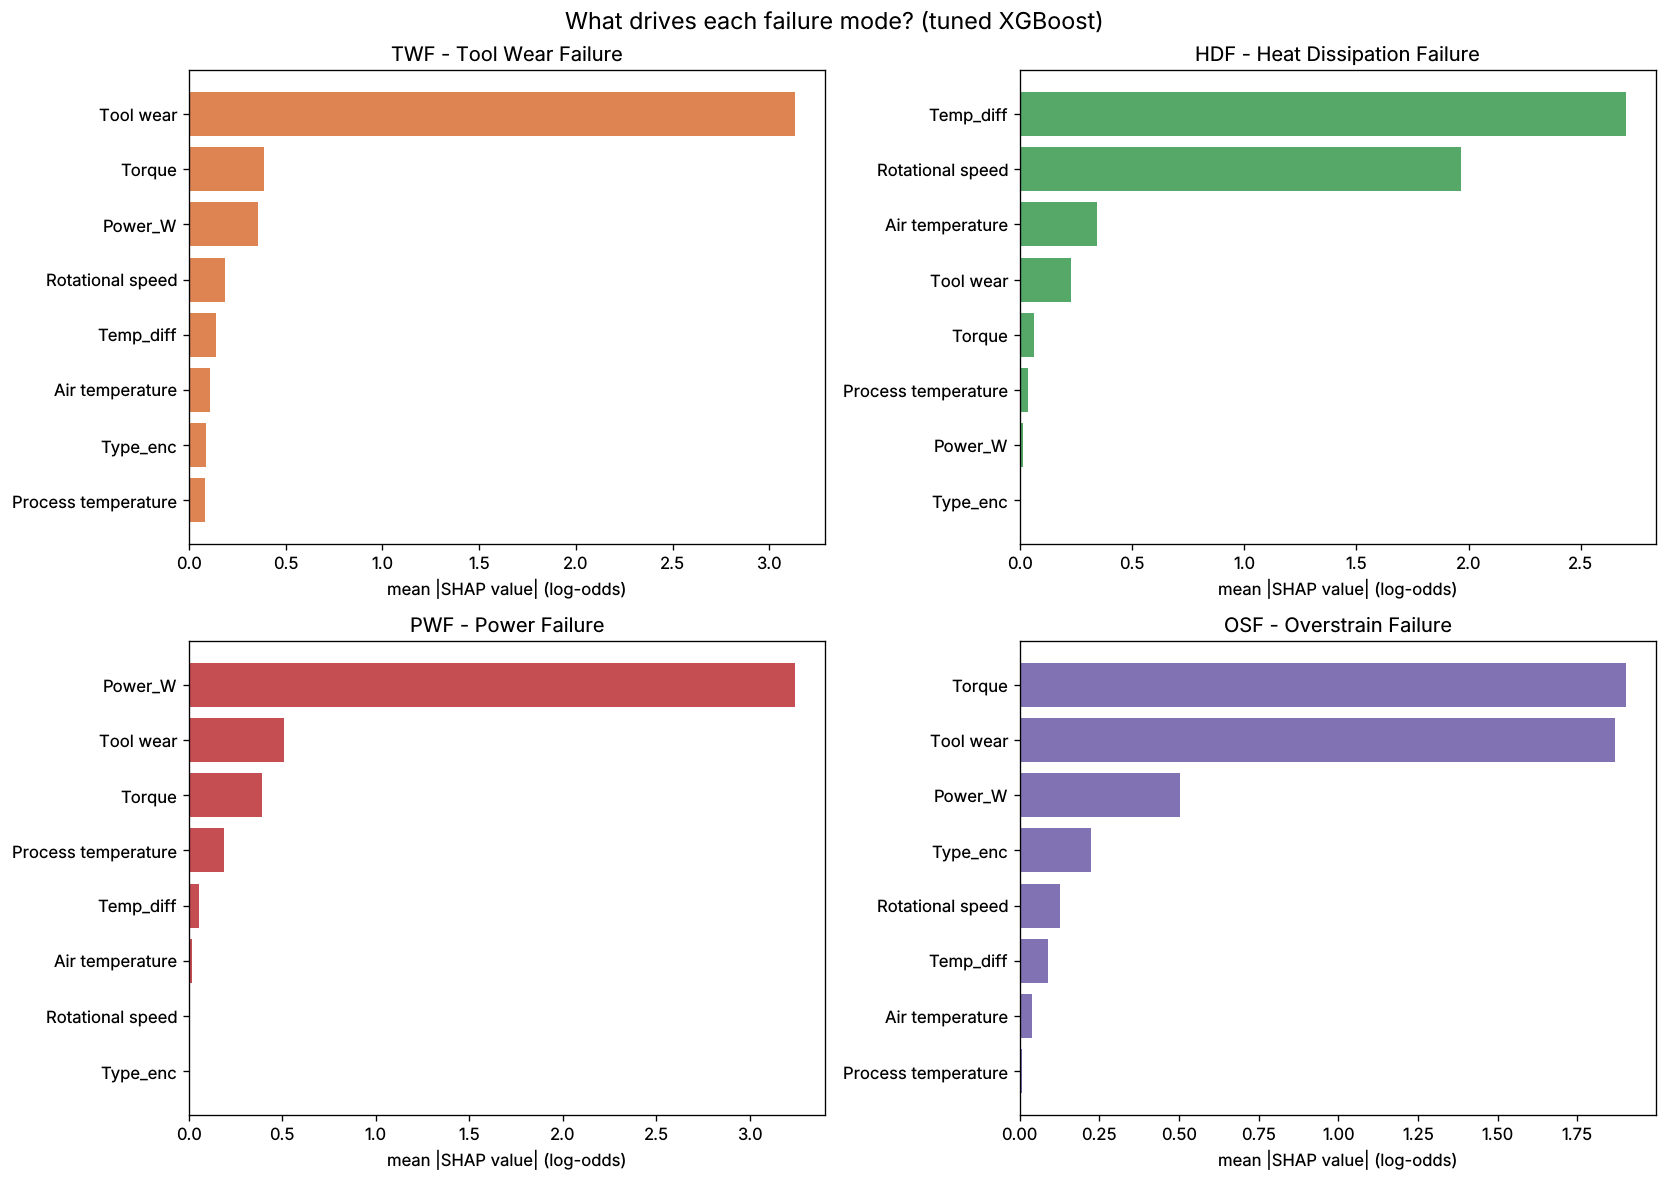

,top driver
TWF,Tool wear
HDF,Temp_diff
PWF,Power_W
OSF,Torque


In [7]:
importance = shap_by_class(model, base[C.FEATURES])
plot_shap_by_class(importance, C.FIGURES_DIR / "shap_per_class.png")
display(Image(C.FIGURES_DIR / "shap_per_class.png"))
importance.idxmax().rename("top driver").to_frame()

## 7. Decision
* **Drifted features → affected class:** torque and tool wear are the top two SHAP drivers of **overstrain (OSF)**, and they are exactly the features that drifted.
* **Retrain:** yes. Include heavy-load data in the reference window, re-tune, and promote the new version only if it beats production on a held-out heavy-load slice.
* **Operational rule (no model needed):** alert when `tool wear × torque > 10,000 min·Nm`. Every overstrain failure in the baseline sits above about 11,000, and 11.4% of heavy-load readings exceed that, against 1.3% normally.
* **Known limitation:** tool-wear failure (TWF) stays unreliable (F1 ≈ 0.07) because there are only 30 real examples. More labelled tool-change events are needed, and SMOTE cannot invent that variety.